![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Evaluation and Interpretation

*Project 2 — Machine Learning: From Data to Predictions*

**Team:** Rizki
**Dataset:** Coffee Quality Institute (CQI) green-coffee reviews, Arabica samples (1,310 rows after cleaning). Scraped Jan 2018 by jldbc (github.com/jldbc/coffee-quality-database). The repo is MIT-licensed; the licence of CQI's underlying data is unclear (see references/sources.json).

---

**This notebook is your report.** It is read on its own, by someone who has not seen notebooks 01 and 02, so it needs the prose as much as the code: the question, the final model, how good it is, where it fails, what drives it, and how far to trust it.

> **Done when:** someone who has never met your project can read this top to bottom and understand what you predicted, how well, compared with what, and where the model should not be used.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. The question and the final model

The framing from notebook 01 and the choice from notebook 02, in a few sentences. Then refit the final pipeline on the whole training set.

**The question.** Before anyone cups a green coffee, can we predict its cupping score from what we know about the lot: country, variety, processing method, altitude, moisture, colour and the two defect counts? A buyer, for example a café like UNTU', could use the prediction to decide which lots to taste first.

**Target and metric.** `Total.Cup.Points`, a number, so this is a regression. The main metric is MAE, the average miss in cup points. R² sits next to it.

**The data.** Arabica lots from the Coffee Quality Institute reviews (scraped in 2018), split once with a fixed seed: 1,048 lots for training, 262 for the test set.

**The final model.** Huber regression (alpha = 10, epsilon = 1.35) inside a preprocessing pipeline. Gaps are filled, numbers scaled and categories one-hot encoded, all learned from the training lots only. Huber is a linear model like Ridge, but it learns from squared error for small misses and absolute error for big ones, so the few very bad lots pull it around less. In cross-validation it beat Ridge on all 5 folds (0.05 cup points on average) and matched a tuned random forest, while staying as simple and as readable as Ridge. Here it is refitted on the whole training set.

In [2]:
from sklearn.linear_model import HuberRegressor
from src.config import PATHS, RANDOM_STATE

df = load_arabica(PATHS["clean_data"])                            # the same Arabica lots as notebooks 01 and 02
X_train, X_test, y_train, y_test = split_once(df, RANDOM_STATE)   # the same split: same seed, same rows
numeric_cols, categorical_cols = get_feature_columns(X_train)
print(f"{len(X_train)} training lots and {len(X_test)} test lots (the test lots stay untouched until section 2)")

# The final model chosen in notebook 02: Huber (alpha = 10, epsilon = 1.35), no extra features
final_model = build_pipeline(HuberRegressor(alpha=10.0, epsilon=1.35, max_iter=1000), numeric_cols, categorical_cols)
final_model.fit(X_train, y_train)          # fitted once on the whole training set
final_model

1048 training lots and 262 test lots (the test lots stay untouched until section 2)


,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


---
## 2. Test once

The final model on the test set, **once**. Compare the score with the cross-validated estimate and with the baseline. If it is much worse than the estimate, say what that tells you.

In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge

cv = make_cv(RANDOM_STATE)                  # the same 5 folds as notebooks 01 and 02
baseline = build_pipeline(DummyRegressor(strategy="mean"), numeric_cols, categorical_cols)
ridge_first = build_pipeline(Ridge(alpha=10.0), numeric_cols, categorical_cols)     # the first choice, kept only as a reference

cv_table = compare_models({"Baseline (mean)": baseline, "Ridge (first choice)": ridge_first, "Huber (final)": final_model},
                          X_train, y_train, cv)
cv_table

,MAE (validation),MAE spread,R2 (validation),R2 spread,MAE (train)
Huber (final),1.596,0.127,0.183,0.033,1.557
Ridge (first choice),1.647,0.118,0.197,0.034,1.596
Baseline (mean),1.819,0.156,-0.003,0.002,1.817


In [4]:
from sklearn.metrics import mean_absolute_error, r2_score

baseline.fit(X_train, y_train)               # the baseline learns the average training score
ridge_first.fit(X_train, y_train)
pred_test = final_model.predict(X_test)      # THE one look at the test set for the final model
pred_baseline = baseline.predict(X_test)
pred_ridge = ridge_first.predict(X_test)     # Ridge was scored on the test set before the switch: shown for honesty, not for choosing

def scores(pred):
    return {"MAE (test)": mean_absolute_error(y_test, pred), "R2 (test)": r2_score(y_test, pred)}

test_table = pd.DataFrame({"Baseline (mean)": scores(pred_baseline),
                           "Ridge (first choice)": scores(pred_ridge),
                           "Huber (final)": scores(pred_test)}).T.round(3)

summary = cv_table[["MAE (validation)", "MAE spread", "R2 (validation)"]].join(test_table)
summary

,MAE (validation),MAE spread,R2 (validation),MAE (test),R2 (test)
Huber (final),1.596,0.127,0.183,1.603,0.175
Ridge (first choice),1.647,0.118,0.197,1.605,0.224
Baseline (mean),1.819,0.156,-0.003,1.830,-0.001


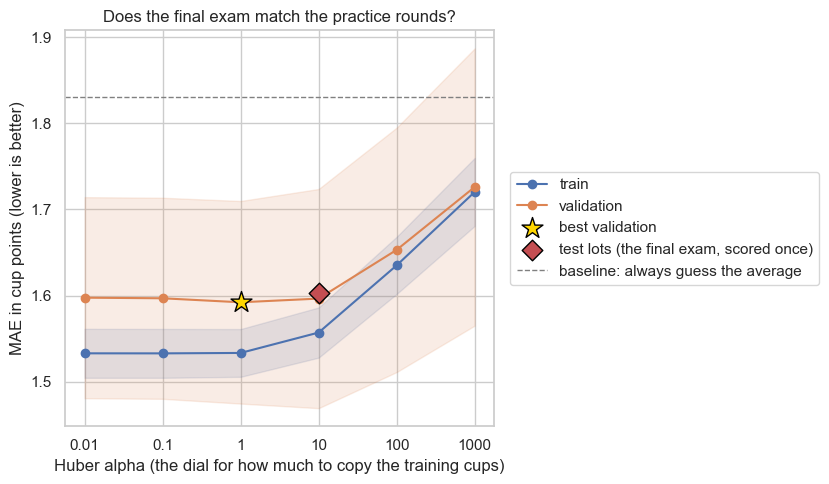

In [5]:
# Practice rounds against the final exam. Alpha is the dial: small = free to copy the training cups, large = held back.
fig, ax = plt.subplots(figsize=(8.5, 5))
plot_validation_curve(ax, final_model, X_train, y_train, cv,
                      "model__alpha", [0.01, 0.1, 1, 10, 100, 1000],
                      "Does the final exam match the practice rounds?",
                      "Huber alpha (the dial for how much to copy the training cups)",
                      log_x=True, scoring="mae")
ax.scatter(10, mean_absolute_error(y_test, pred_test), marker="D", s=110, color="C3", edgecolor="black", zorder=6,
           label="test lots (the final exam, scored once)")
ax.axhline(mean_absolute_error(y_test, pred_baseline), color="grey", linestyle="--", linewidth=1,
           label="baseline: always guess the average")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))          # legend beside the chart, not on top of the lines
plt.tight_layout()
plt.show()

**How to read it.** Each dot is the average miss in cup points, so lower is better and the numbers match the table above. Blue is Huber scored on the lots it learned from. Orange is Huber scored on lots held out in the five practice rounds (cross-validation), and the shaded band shows how much the five rounds disagreed. The gold star marks the best practice score. The red diamond is the final exam: the 262 test lots, scored once. The dashed line is the baseline, which gives every lot the average score.

**Takeaway:** The final exam matched the practice rounds. Huber missed by 1.603 cup points on the test lots against 1.596 in the practice rounds (the five rounds differed by ±0.127), and both beat the baseline's 1.83. Alpha holds Huber back: from 0.01 to 10 it changes nothing (the best practice score is at alpha = 1, only 0.004 better than at 10), and above that Huber is held back so much that the miss grows to about 1.65 at 100 and 1.73 at 1000.

**Against Ridge.** Ridge, the first choice, missed by 1.605 on the same test lots, a tie with Huber, although cross-validation had put Ridge 0.05 behind (1.647). Huber's test score matches its cross-validated estimate, while Ridge scored 0.04 better on the test lots than its estimate, which is inside the fold-to-fold spread. So on 262 lots the two cannot be told apart by MAE, and Ridge is ahead on R² (0.224 against 0.175), because R² punishes big misses and Huber deliberately pays them less attention. I chose Huber from cross-validation before this look and I am not changing the choice because of the test score. What the test set shows is that the cost-function gain is too small to be confirmed on 262 lots.

---
## 3. Where it goes wrong

Classification: the confusion matrix and the per-class results, at your chosen threshold. Regression: the residuals, and where they are largest. Look at a few of the worst predictions and say what they have in common.

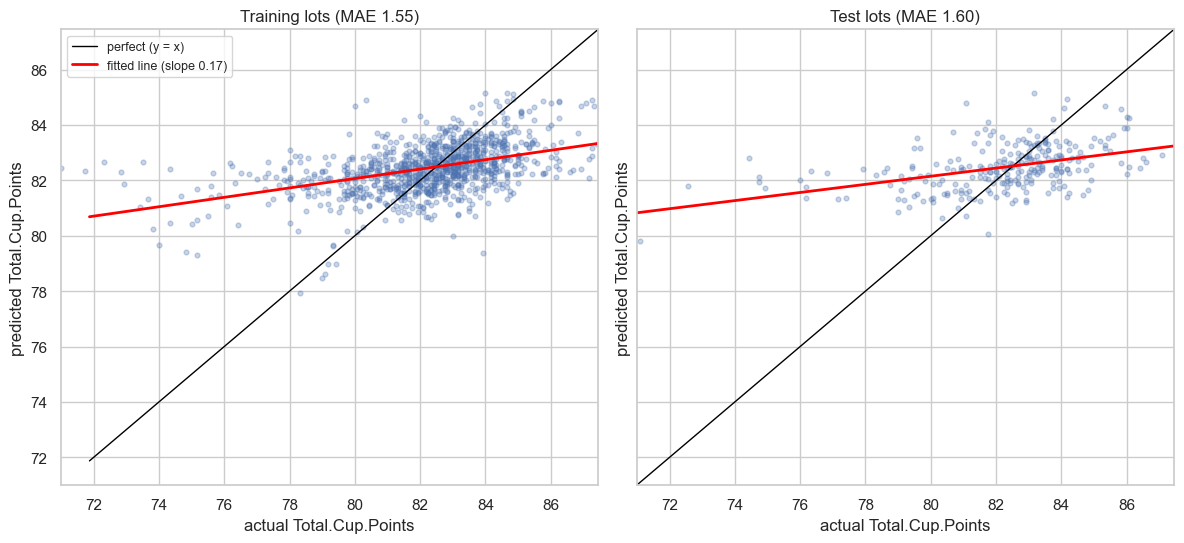

In [6]:
pred_train = final_model.predict(X_train)      # the model's guesses on lots it has already seen

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), sharex=True, sharey=True)
plot_predicted_vs_actual(axes[0], y_train, pred_train, f"Training lots (MAE {mean_absolute_error(y_train, pred_train):.2f})")
plot_predicted_vs_actual(axes[1], y_test, pred_test, f"Test lots (MAE {mean_absolute_error(y_test, pred_test):.2f})")
axes[0].legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

**Predicted against actual.** The red fitted line has a slope of 0.17 on the training lots (the test lots look just as flat), far flatter than the black perfect line. Huber plays safe: on the test lots it predicts between about 80 and 85 for lots that really scored anywhere from 68 to 87. It puts lots in roughly the right order but pulls everything toward the average, like a cupper who gives nearly every coffee an 82.

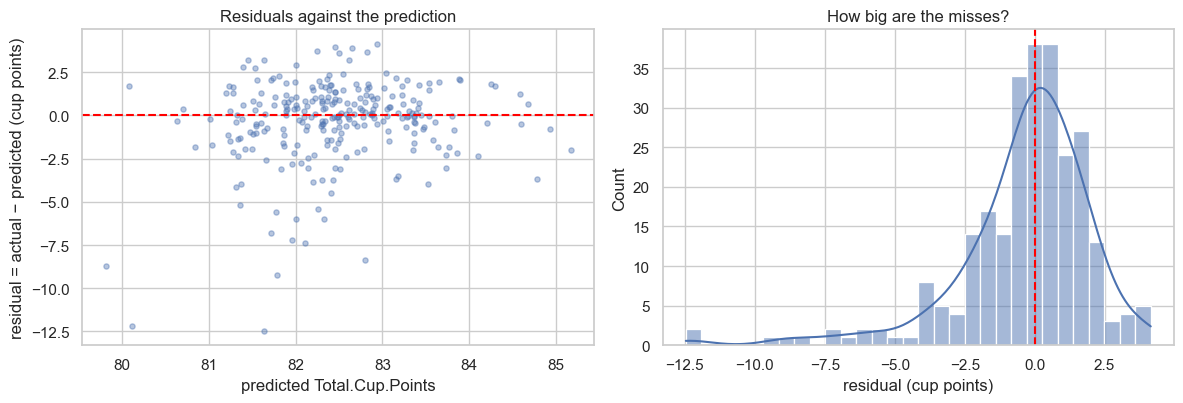

Lots within 1 cup point(s) of the truth: 47 %
Lots within 2 cup point(s) of the truth: 75 %
Lots within 3 cup point(s) of the truth: 86 %
Largest miss: 12.5 cup points


In [7]:
residuals = y_test - pred_test                 # actual minus predicted; below 0 = we guessed too high

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(pred_test, residuals, alpha=0.4, s=14)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("predicted Total.Cup.Points")
axes[0].set_ylabel("residual = actual − predicted (cup points)")
axes[0].set_title("Residuals against the prediction")
sns.histplot(residuals, bins=30, kde=True, ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("residual (cup points)")
axes[1].set_title("How big are the misses?")
plt.tight_layout()
plt.show()

for points in [1, 2, 3]:
    print(f"Lots within {points} cup point(s) of the truth: {(residuals.abs() <= points).mean() * 100:.0f} %")
print(f"Largest miss: {residuals.abs().max():.1f} cup points")

**Takeaway:** Most misses are small: 47 % of the test lots are within 1 cup point, 75 % within 2 and 86 % within 3. The histogram peaks just above 0 and has a long tail to the left: a few lots that Huber guessed far too high. The biggest miss is 12.5 cup points.

In [8]:
worst = X_test.copy()
worst["actual"] = y_test
worst["predicted"] = pred_test.round(2)
worst["miss"] = (y_test - pred_test).round(2)
worst.reindex(worst["miss"].abs().sort_values(ascending=False).index).head(10)

,Moisture,altitude_mean_meters,Category.One.Defects,Category.Two.Defects,Country.of.Origin,Variety,Processing.Method,Color,actual,predicted,miss
1305,0.10,1450.0,0,4,Honduras,Catuai,Washed / Wet,Green,69.17,81.63,-12.46
1307,0.14,350.0,8,16,Haiti,Typica,Natural / Dry,Blue-Green,67.92,80.11,-12.19
1296,0.11,NaN,5,9,United States (Hawaii),Hawaiian Kona,Natural / Dry,Green,72.58,81.79,-9.21
1299,0.12,800.0,4,24,Mexico,Mundo Novo,Washed / Wet,Green,71.08,79.81,-8.73
1286,NaN,NaN,1,2,United States (Hawaii),Hawaiian Kona,Natural / Dry,Blue-Green,74.42,82.80,-8.38
1283,0.11,NaN,0,8,Guatemala,Bourbon,Washed / Wet,NaN,74.75,82.11,-7.36
1284,0.11,NaN,0,10,Guatemala,Bourbon,Washed / Wet,NaN,74.75,81.96,-7.21
1281,NaN,1500.0,0,6,Mexico,Typica,Washed / Wet,NaN,74.92,81.71,-6.79
1271,0.11,1350.0,0,7,Honduras,Pacas,Natural / Dry,Green,76.00,82.01,-6.01
1265,0.11,NaN,0,5,Guatemala,Bourbon,Washed / Wet,NaN,76.33,82.33,-6.00


**The ten worst misses.** All ten go the same way: the lot scored far below what Huber expected (actual 68 to 76, predicted 80 to 83). Five of the ten have no altitude on record (about one lot in five overall), so the model assumes an average lot. Three carry many category-two defects (10, 16 and 24, against an average of 3.6), and a straight-line model can only dock a fixed amount per defect. The lots that were secretly bad were the ones the model could not see. They are the same ten lots Ridge missed most; Huber misses the two worst by slightly more (12.5 and 12.2 points against 11.7 and 11.4).

**Misses by country and by true score.**
- By country (the 9 countries with 10 or more test lots): Honduras (MAE 2.27), Guatemala (2.07) and Hawaii (1.98) are hardest, Colombia is easiest (0.99, with 45 lots), against 1.60 for all lots. With 10 to 45 lots per country, neighbours in the ranking are too close to separate, so only the two ends are worth naming.
- By true score, which is the key finding: in the middle the model is good (0.6 to 1.2 cup points off for lots scoring 80 to 84), but lots that really scored below 80 are missed by 4.5 points (predicted too high), and lots of 84 and up by 2.1 (predicted too low). The model cannot see the duds or the stars. Ridge missed the weakest lots by 4.0, so Huber is about half a point worse there, which is what you would expect from a model that pays big misses less attention.
- **Business reading:** use it to decide what to taste first, not to screen out lots. A lot predicted at 81 can really be a 72.

                              lots   MAE  bias
group                                         
Honduras                        12  2.27 -1.70
Guatemala                       35  2.07 -1.10
United States (Hawaii)          20  1.98 -1.01
Mexico                          39  1.71 -0.57
Tanzania, United Republic Of    10  1.42  0.20
Indonesia                       10  1.38 -0.87
Taiwan                          22  1.38  0.63
Brazil                          20  1.11  0.92
Colombia                        45  0.99 -0.26
           lots   MAE  bias
group                      
below 80     39  4.52 -4.52
80 to 82     57  1.16 -1.07
82 to 84    116  0.64  0.37
84 and up    50  2.06  2.01


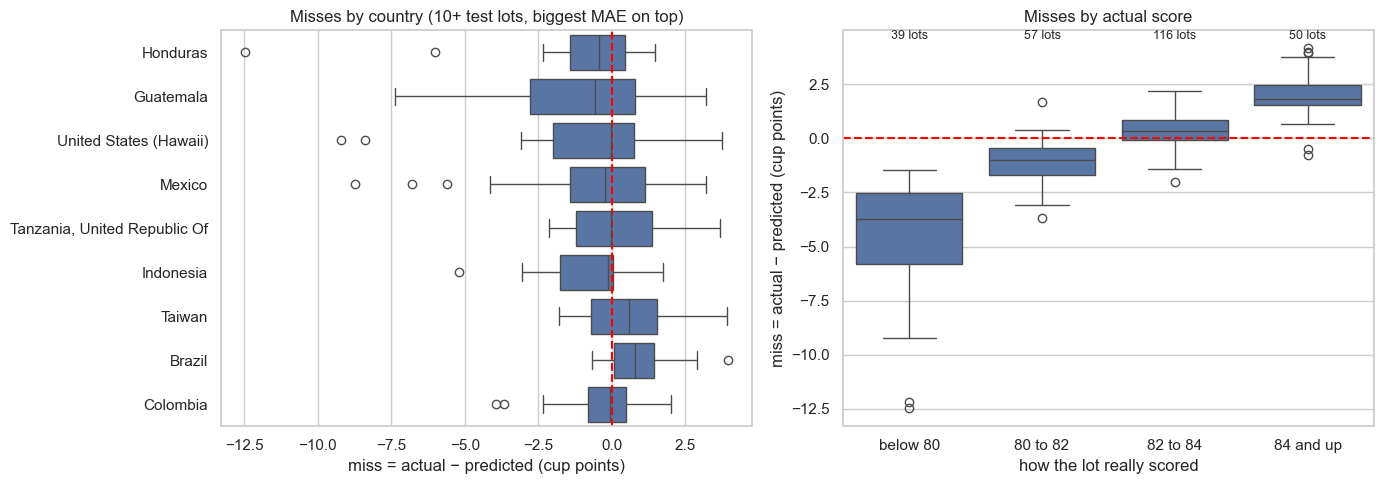

In [9]:
by_country = error_by_group(X_test["Country.of.Origin"], y_test, pred_test, min_lots=10)
band_names = ["below 80", "80 to 82", "82 to 84", "84 and up"]
score_band = pd.cut(y_test, [0, 80, 82, 84, 100], right=False, labels=band_names)
by_band = error_by_group(score_band, y_test, pred_test).loc[band_names]
print(by_country)
print(by_band)

misses = pd.DataFrame({"country": X_test["Country.of.Origin"].values,
                       "band": score_band.values,
                       "miss": residuals.values})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=misses[misses["country"].isin(by_country.index)], y="country", x="miss",
            order=by_country.index, ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_xlabel("miss = actual − predicted (cup points)")
axes[0].set_ylabel("")
axes[0].set_title("Misses by country (10+ test lots, biggest MAE on top)")
sns.boxplot(data=misses, x="band", y="miss", order=band_names, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
for x, lots in enumerate(by_band["lots"]):
    axes[1].text(x, axes[1].get_ylim()[1], f"{lots} lots", ha="center", va="top", fontsize=9)
axes[1].set_xlabel("how the lot really scored")
axes[1].set_ylabel("miss = actual − predicted (cup points)")
axes[1].set_title("Misses by actual score")
plt.tight_layout()
plt.show()

**Takeaway:** Huber is at its best in the middle (misses of about 0.6 to 1.2 for lots that scored 80 to 84). Lots that really scored below 80 are guessed about 4.5 points too high, and lots of 84 and up about 2 points too low. Read the score-band panel with care: any model that pulls guesses toward the average misses the extremes in this view. Its use is to say which cups the model cannot see, not to compare models.

Right side of the 80 line: 0.855
Always saying 'specialty' (no model at all): 0.851
Sub-80 lots caught: 3% | flagged lots that really are sub-80: 100%


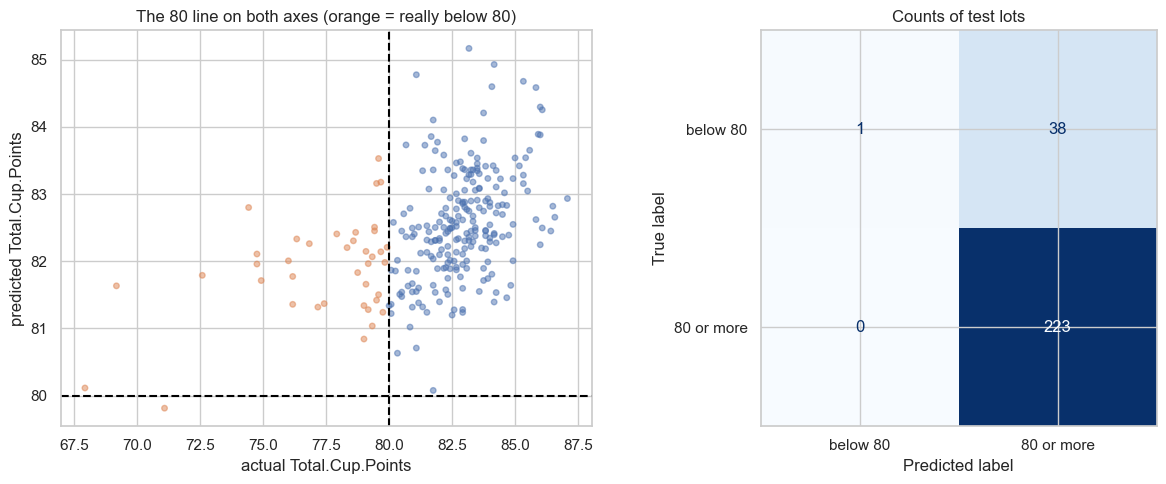

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score

actual_specialty = y_test >= 80                # what the cupping said
says_specialty = pred_test >= 80               # what the model said

print("Right side of the 80 line:", round(accuracy_score(actual_specialty, says_specialty), 3))
print("Always saying 'specialty' (no model at all):", round(actual_specialty.mean(), 3))
print("Sub-80 lots caught:", f"{recall_score(~actual_specialty, ~says_specialty):.0%}",
      "| flagged lots that really are sub-80:", f"{precision_score(~actual_specialty, ~says_specialty, zero_division=0):.0%}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
axes[0].scatter(y_test, pred_test, c=np.where(actual_specialty, "C0", "C1"), alpha=0.5, s=16)
axes[0].axvline(80, color="black", linestyle="--")
axes[0].axhline(80, color="black", linestyle="--")
axes[0].set_xlabel("actual Total.Cup.Points")
axes[0].set_ylabel("predicted Total.Cup.Points")
axes[0].set_title("The 80 line on both axes (orange = really below 80)")
ConfusionMatrixDisplay.from_predictions(actual_specialty, says_specialty, display_labels=["below 80", "80 or more"],
                                        cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title("Counts of test lots")
plt.tight_layout()
plt.show()

**Takeaway:** At the 80-point line Huber flags a single test lot as below 80, and that lot really was weak, but it catches only 1 of the 39 lots that really scored below 80 (3 %): the other 38 go through. Its accuracy (0.855) is one lot better than "always say specialty" (0.851). Ridge flagged 6 lots and caught 3 of the 39. So use it to decide which lots to taste first, not to screen weak lots out.

---
## 4. What drives the predictions

Permutation importance on the test set, or an equivalent. Strongly related features share their importance, so read the ranking with care, and translate it into business terms.

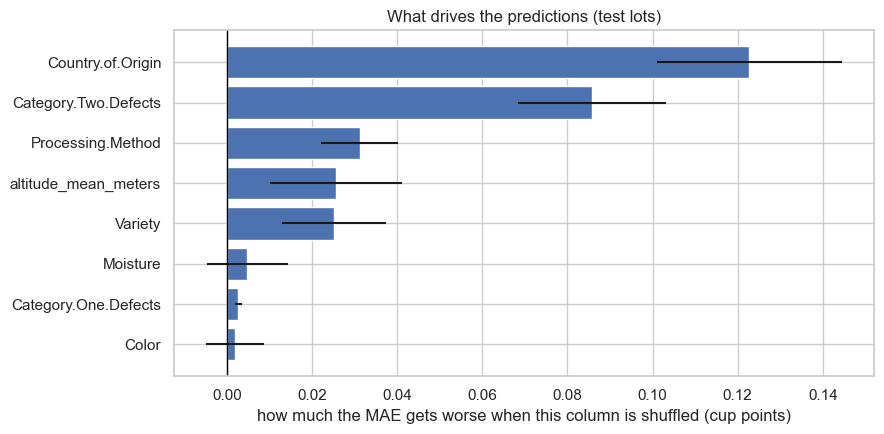

In [11]:
from sklearn.inspection import permutation_importance

result = permutation_importance(final_model, X_test, y_test, scoring="neg_mean_absolute_error",
                                n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"feature": X_test.columns, "MAE gets worse by": result.importances_mean,
                           "spread": result.importances_std}).sort_values("MAE gets worse by")

plt.figure(figsize=(9, 4.5))
plt.barh(importance["feature"], importance["MAE gets worse by"], xerr=importance["spread"])
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("how much the MAE gets worse when this column is shuffled (cup points)")
plt.title("What drives the predictions (test lots)")
plt.tight_layout()
plt.show()

**Takeaway (bars):** Country.of.Origin and Category.Two.Defects move the predictions most: shuffling either one makes the average miss about 0.12 and 0.09 cup points bigger. Processing.Method comes next (about 0.03), then altitude and Variety (about 0.025 each; their error bars overlap, so read them as tied). Moisture, Color and Category.One.Defects barely matter: their bars sit at about 0, and for Moisture and Color the error bars reach below zero. Countries and processing methods overlap, so they share credit; read the ranking as groups of features, not exact places. In coffee terms: where a lot was grown and how many secondary defects the sample has tell the model most, and the processing method, altitude and variety add a little.

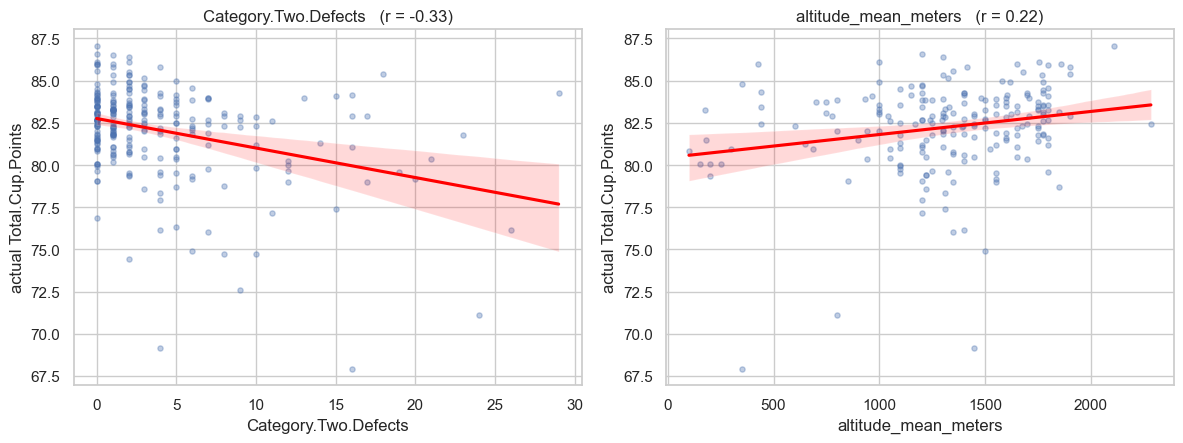

In [12]:
test_lots = X_test.copy()
test_lots[TARGET] = y_test

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, col in zip(axes, ["Category.Two.Defects", "altitude_mean_meters"]):
    r = test_lots[[col, TARGET]].corr().iloc[0, 1]     # r = how straight the link is
    sns.regplot(data=test_lots, x=col, y=TARGET, ax=ax, scatter_kws={"alpha": 0.35, "s": 14}, line_kws={"color": "red"})
    ax.set_title(f"{col}   (r = {r:.2f})")
    ax.set_ylabel("actual Total.Cup.Points")
plt.tight_layout()
plt.show()

**Takeaway (scatter):** More secondary defects go with lower scores, and higher altitude goes with higher scores. These are the same directions as in notebook 02, now on lots the model has never seen.

---
## 5. Save, reload, predict

Save the fitted pipeline (and the threshold) with `joblib` into `models/`, reload it, and predict for a few new rows. This is your demo on Friday.

**What is saved.** One file, `models/final_model.joblib`, holding the whole pipeline: the preprocessing (gap filling, scaling and one-hot encoding, all learned from the training lots) and Huber regression. A regression has no threshold to save. The 80-point line is only a way of reading a prediction, not part of the model. The `models/` folder is not committed to git.

In [13]:
import os
import joblib

os.makedirs(PATHS["model_dir"], exist_ok=True)
model_file = os.path.join(PATHS["model_dir"], "final_model.joblib")
joblib.dump(final_model, model_file)                       # the whole pipeline in one file: preprocessing and Huber

reloaded = joblib.load(model_file)                         # what the demo does: no refitting, no training data
print("Saved to: models/final_model.joblib")
print("Reloaded:", type(reloaded.named_steps["model"]).__name__,
      "| same predictions as before saving:", bool(np.allclose(reloaded.predict(X_test), pred_test)))

Saved to: models/final_model.joblib
Reloaded: HuberRegressor | same predictions as before saving: True


In [14]:
# Four made-up lots a buyer might ask about. The columns are the ones the model was trained on.
new_lots = pd.DataFrame([
    {"Moisture": 0.11, "altitude_mean_meters": 1700, "Category.One.Defects": 0, "Category.Two.Defects": 1,
     "Country.of.Origin": "Colombia", "Variety": "Caturra", "Processing.Method": "Washed / Wet", "Color": "Green"},
    {"Moisture": 0.10, "altitude_mean_meters": 1500, "Category.One.Defects": 0, "Category.Two.Defects": 3,
     "Country.of.Origin": "Guatemala", "Variety": "Bourbon", "Processing.Method": "Washed / Wet", "Color": "Green"},
    {"Moisture": 0.12, "altitude_mean_meters": 900, "Category.One.Defects": 2, "Category.Two.Defects": 9,
     "Country.of.Origin": "Brazil", "Variety": "Typica", "Processing.Method": "Natural / Dry", "Color": "Green"},
    {"Moisture": 0.11, "altitude_mean_meters": np.nan, "Category.One.Defects": 0, "Category.Two.Defects": 2,    # altitude not on record
     "Country.of.Origin": "Colombia", "Variety": "Caturra", "Processing.Method": "Washed / Wet", "Color": "Green"},
])[X_train.columns]                                        # same columns, same order as the training table

for column in CATEGORICAL_FEATURES:                        # a misspelt label would be treated as a rare category, so check
    unknown = set(new_lots[column]) - set(X_train[column].dropna().unique())
    print(column, "| labels the model has never seen:", unknown or "none")

predicted = reloaded.predict(new_lots)
new_lots["predicted cup points"] = predicted.round(1)
new_lots["probably between"] = [f"{p - 2:.0f} and {p + 2:.0f}" for p in predicted]     # 75 % of test lots were within 2 points
new_lots[["Country.of.Origin", "Processing.Method", "altitude_mean_meters", "predicted cup points", "probably between"]]

Country.of.Origin | labels the model has never seen: none
Variety | labels the model has never seen: none
Processing.Method | labels the model has never seen: none
Color | labels the model has never seen: none


,Country.of.Origin,Processing.Method,altitude_mean_meters,predicted cup points,probably between
0,Colombia,Washed / Wet,1700.0,83.3,81 and 85
1,Guatemala,Washed / Wet,1500.0,82.6,81 and 85
2,Brazil,Natural / Dry,900.0,81.3,79 and 83
3,Colombia,Washed / Wet,NaN,83.0,81 and 85


**Takeaway:** The saved file is the whole pipeline, so the demo only needs `joblib.load` and a table with the same eight columns: no training data and no refitting. The four example lots come out between 81.3 and 83.3, the high Colombian lot on top and the Brazilian natural with nine category-two defects at the bottom. The Colombian lot with no altitude on record still gets a prediction (83.0), because the pipeline fills the gap with the median altitude from the training lots. Read each prediction with its range: 75 % of the test lots were within 2 cup points, and the model cannot see the duds or the stars.

---
## 6. Conclusions and limitations

Would you use this model, and for what? Where should it not be trusted? What would you do with another week? Knowing the limits of your own model is part of the grade.

**Would I use it?** Yes, for one job: deciding which green-coffee lots to cup first. No, for rejecting lots or for quoting a score.

**Why yes.** On 262 lots it had never seen, Huber missed by 1.603 cup points on average, against 1.830 for the baseline that always guesses the average: about 12 % better. That matched the 1.596 (± 0.127) expected from cross-validation, so the estimate can be trusted. 75 % of the lots landed within 2 cup points and 86 % within 3. The check below asks the practical question: if there is only time to cup one lot in five, are the lots Huber likes best really the good ones? It finds 17 of the 52 truly best lots (33 %), against about 20 % for a blind pick, and the lots it likes best really average 83.5 cup points against 82.1 for all test lots.

**Huber or Ridge.** On these test lots the two linear models tie on MAE (1.603 and 1.605). Huber won in cross-validation, on all 5 folds, and was chosen for that before the test set was looked at. The test set did not confirm the gain, and Huber is a little worse on the weakest lots and on R². A buyer would not notice the difference.

**Why not more.** R² is 0.175, so Huber explains less than a fifth of the differences between lots. It pulls every prediction toward the average (the fitted line has a slope of 0.17), so on the test lots it never predicts below 80 or above 85.

**What a mistake costs.** The 80-point line shows it. Huber flags only 1 of the 262 test lots as below 80, and that one is right, but 38 of the 39 lots that really scored below 80 go through. As a gatekeeper it is useless. As a ranking, a wrong guess costs only one cupping that was not needed.

**Recommendation for a buyer such as UNTU'.** Let Huber order the cupping table, and still cup every lot you might buy. Do not use the predicted score as a quality claim or to set a price. I would only let it screen lots if it caught most of the weak ones, and that needs better information about each lot (see the next steps below).

In [15]:
# The use we recommend: cup first the lots Huber ranks highest. Does that find the really good lots?
ranked = pd.DataFrame({"actual": y_test.values, "predicted": pred_test})     # one row per test lot
n = int(len(ranked) * 0.2)                                                   # one lot in five

picked = ranked.nlargest(n, "predicted")              # the lots Huber would have us cup first
best = ranked.nlargest(n, "actual")                   # the lots that really cupped best
found = len(set(picked.index) & set(best.index))      # lots that appear in both lists

print(f"Cupping the {n} lots Huber likes best finds {found} of the {n} truly best lots ({found / n:.0%}). "
      f"Picking {n} lots blindly would find about {n / len(ranked):.0%}.")
print(f"The lots Huber likes best really average {picked['actual'].mean():.1f} cup points, "
      f"against {ranked['actual'].mean():.1f} for all test lots.")

Cupping the 52 lots Huber likes best finds 17 of the 52 truly best lots (33%). Picking 52 lots blindly would find about 20%.
The lots Huber likes best really average 83.5 cup points, against 82.1 for all test lots.


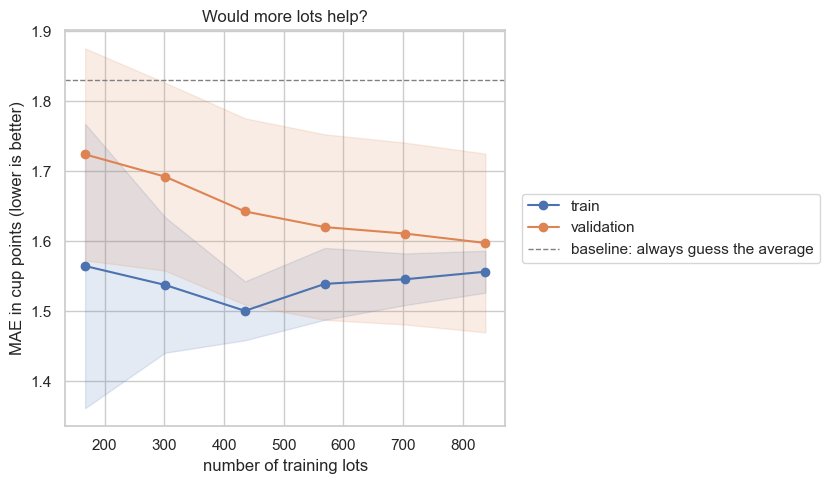

In [16]:
# Would more lots help? Huber trained on a growing number of lots, scored on lots it did not see.
fig, ax = plt.subplots(figsize=(8.5, 5))
plot_learning_curve(ax, final_model, X_train, y_train, cv,
                    "Would more lots help?", RANDOM_STATE, scoring="mae")
ax.axhline(mean_absolute_error(y_test, pred_baseline), color="grey", linestyle="--", linewidth=1,
           label="baseline: always guess the average")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

**Where it should not be trusted**
- Lots that really score below 80: guessed about 4.5 points too high.
- Lots of 84 and up: guessed about 2 points too low.
- Countries with few lots: only 9 countries had 10 or more test lots, and their misses range from about 1.0 (Colombia) to 2.3 (Honduras).

**What the data holds for**
- Arabica lots from the Coffee Quality Institute reviews, scraped in January 2018. It says nothing about harvests since then, and nothing about Robusta.
- Eight columns only: country, variety, processing method, altitude, moisture, colour and two defect counts. The table has no land cost, rainfall, shade or harvest year, which are what a buyer would most like to know.
- Gaps: moisture is missing in about 23 % of the lots (252 lots had a moisture of exactly 0.0, read as "not measured"), altitude and colour in about 20 %, variety in 15 % and processing method in 12 %. The pipeline fills them with the median or a "missing" label, so the model cannot tell an average lot from one that was never measured. 31 lots with a moisture above 0.13 are kept in, and whether that is a really wet lot or a typing error is still open.
- A small test set: 262 lots, so the country and score-band results rest on 10 to 45 lots each. Read the two ends of those rankings, not the middle.
- The target is a person's score for a sample cup, so part of the miss may be noise that no model can remove.
- Licence: the repository is MIT-licensed, but the licence of the underlying CQI data is unclear, so check it before any commercial use.

**More lots?** The orange line (lots held out) improves quickly up to about 450 lots (MAE from 1.72 to 1.64), then more slowly: about 1.62 at 570 lots and 1.60 at 840. It is still creeping down at the right edge, but the gap to the practice line is only about 0.04, so more lots like these would add only a little. The line stops at about 840 lots because each practice round trains on 80 % of the 1,048 training lots. A better prediction would need better information about each lot, such as a finer location than the country, the harvest year or the weather, not simply more of the same columns.

**With another week**
1. **Better information, not more of the same.** A finer location than the country, the harvest year and the weather for that place and year. The learning curve says more lots like these would add little.
2. **A separate answer for the 80-point question.** Flag a lot when its predicted score is below a cut-off higher than 80, chosen from cross-validation on the training lots. Notebook 02 (section 7) shows the trade-off: at a cut-off of 82 Huber catches 59 % of the sub-80 lots, but 29 % of all lots would get a second cupping and only 27 % of those would really be weak.
3. **Test on newer lots**, with a split by time, to see whether a model learned from 2018 reviews still holds.
4. **Show every prediction with its range**, as in section 5, so a buyer sees the uncertainty.

---
## Image option

If you chose the flower photos: evaluate the chosen model once on the test set; show the confusion matrix, per-class precision and recall, and a gallery of misclassified photos with a reading of why; save it as a `.keras` file, reload it and predict a photo it has never seen.